Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

Objective: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

Dataset: This lab utilizes the Amazon UK product dataset which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.



In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
df = pd.read_csv(r"C:\Users\bootcamp\week5\day1\lab-eda-bivariate/amz_uk_price_prediction_dataset.csv")

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.shape

(2443651, 9)

In [5]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

Part 1: Analyzing Best-Seller Trends Across Product Categories
Objective: Understand the relationship between product categories and their best-seller status.

Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.
Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [6]:
#1.1 Create a crosstab between the product category and the isBestSeller status.
pd.crosstab(df['category'], df['isBestSeller'], margins=True)

isBestSeller,False,True,All
category,,,
3D Printers,247,1,248
3D Printing & Scanning,4065,2,4067
Abrasive & Finishing Products,245,5,250
Action Cameras,1696,1,1697
Adapters,251,3,254
...,...,...,...
Window Treatments,234,5,239
Women,17559,213,17772
Women's Sports & Outdoor Shoes,1939,20,1959


In [7]:
#1.2 Are there categories where being a best-seller is more prevalent?

crosstab = pd.crosstab(df['category'], df['isBestSeller'])
best_seller_col = crosstab.columns.max() 
best_seller_prop = crosstab[best_seller_col] / crosstab.sum(axis=1)
best_seller_prop.sort_values(ascending=False).round(3)





category
Grocery                           0.058
Smart Home Security & Lighting    0.058
Health & Personal Care            0.058
Mobile Phone Accessories          0.042
Power & Hand Tools                0.035
                                  ...  
Bedding Collections               0.000
CPUs                              0.000
CD, Disc & Tape Players           0.000
Blank Media Cases & Wallets       0.000
eBook Readers & Accessories       0.000
Length: 296, dtype: float64

In [8]:
# 2.1 - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.


In [9]:
print(crosstab)

isBestSeller                    False  True 
category                                    
3D Printers                       247      1
3D Printing & Scanning           4065      2
Abrasive & Finishing Products     245      5
Action Cameras                   1696      1
Adapters                          251      3
...                               ...    ...
Wind Instruments                  243      7
Window Treatments                 234      5
Women                           17559    213
Women's Sports & Outdoor Shoes   1939     20
eBook Readers & Accessories       246      0

[296 rows x 2 columns]


In [10]:
from scipy.stats import chi2_contingency

chi2_stat, p_value, dof, expected = chi2_contingency(crosstab)

print(f"Chi2 statistic: {chi2_stat:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Degrees of freedom: {dof}")

Chi2 statistic: 36540.2027
P-value: 0.0000
Degrees of freedom: 295


In [11]:
# Very large value, indicating the observed counts differ a lot from what would be expected if category and best-seller status were independent
# Best-seller distribution is not independent of product category: some categories have systematically higher or lower best-seller rates than others

In [12]:
# 2.1 Compute Cramér's V to understand the strength of association between best-seller status and category.


In [13]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
chi2_stat, _, dof, _ = chi2_contingency(crosstab)
n = crosstab.values.sum()
min_dim = min(crosstab.shape) - 1 
cramers_v = np.sqrt(chi2_stat / (n * min_dim))
print(f"Cramér's V: {cramers_v:.3f}")



Cramér's V: 0.122


In [14]:
# Cramér's V of 0.122 indicates a weak association between product category and best-seller status 

In [15]:
#3 Visualize the relationship between product categories and the best-seller status using a stacked bar chart

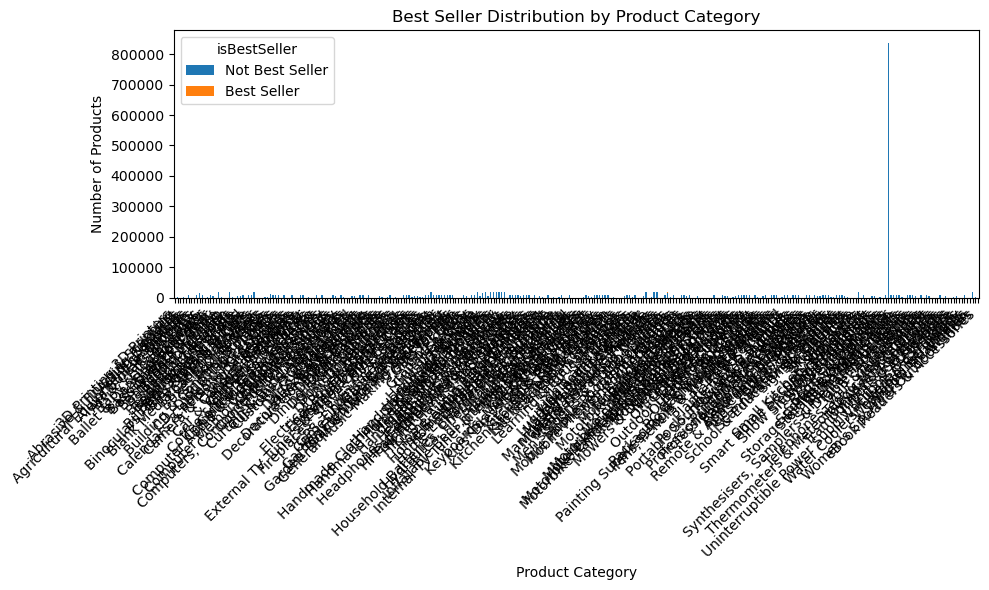

In [16]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
crosstab.plot(kind='bar', stacked=True, figsize=(10, 6))
plt.title('Best Seller Distribution by Product Category')
plt.ylabel('Number of Products')
plt.xlabel('Product Category')
plt.legend(title='isBestSeller', labels=['Not Best Seller', 'Best Seller'])
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

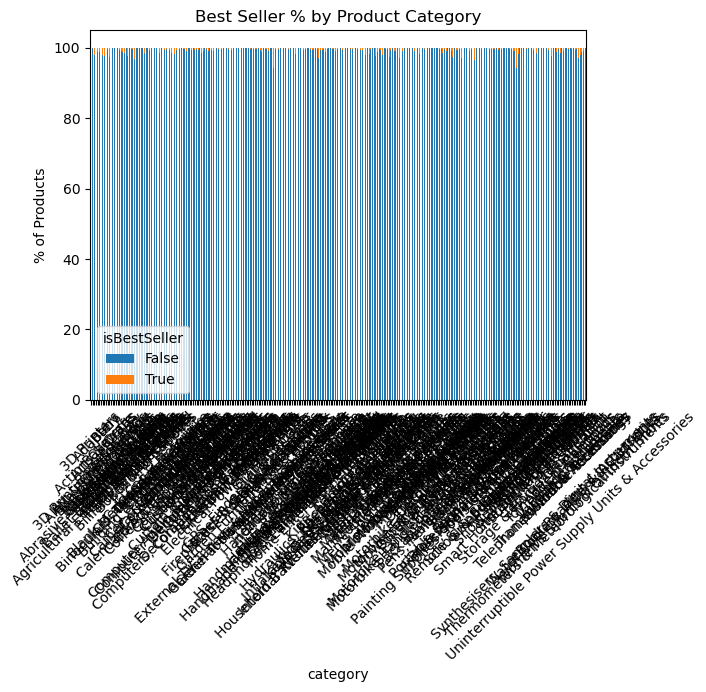

In [17]:
(crosstab.div(crosstab.sum(axis=1), axis=0) * 100).plot(kind='bar', stacked=True)
plt.title('Best Seller % by Product Category')
plt.ylabel('% of Products')
plt.legend(title='isBestSeller')
plt.xticks(rotation=45)
plt.show()

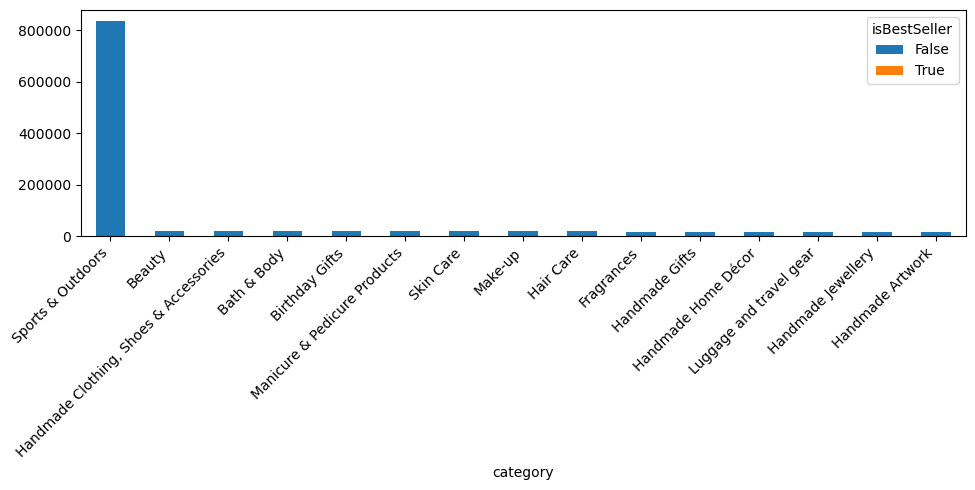

In [18]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
top_n = 15  
top_categories = crosstab.sum(axis=1).sort_values(ascending=False).head(top_n).index
crosstab_top = crosstab.loc[top_categories]
crosstab_top.plot(kind='bar', stacked=True, figsize=(10, 5))
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


Part 2: Exploring Product Prices and Ratings Across Categories and Brands
For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.



In [19]:
#.0 Preliminary Step: Remove outliers in product prices
df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [20]:
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr = q3 - q1

In [21]:
iqr

np.float64(36.0)

In [22]:
lower_outlier = q1 - 1.5 * iqr
upper_outlier = q3 + 1.5 * iqr


In [23]:
lower_outlier

np.float64(-44.01)

In [24]:
upper_outlier

np.float64(99.99000000000001)

In [25]:
df_no_outliers = df[(df['price'] >= lower_outlier) & (df['price'] <= upper_outlier)]
df_no_outliers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [26]:
skewness_price = df['price'].skew()
kurtosis_price = df['price'].kurtosis()
skewness_price, kurtosis_price

(np.float64(27.492977566280338), np.float64(4241.616412866518))

# 1.1 Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.

In [27]:
top20 = (df_no_outliers['category']
         .value_counts()
         .head(20)
         .index)

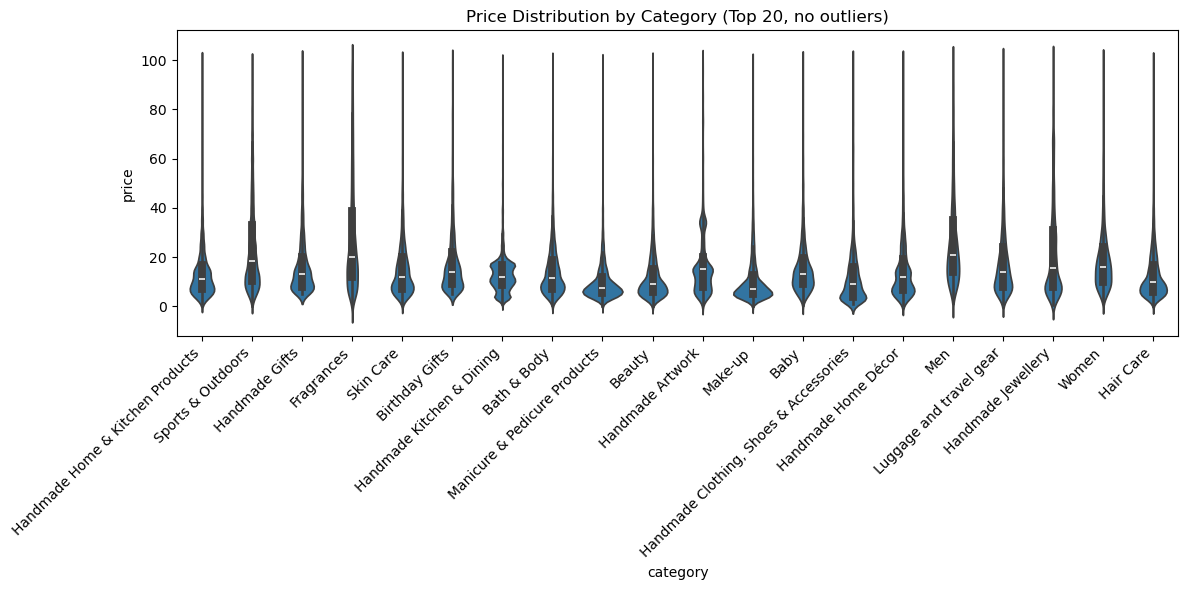

In [28]:
plt.figure(figsize=(12, 6))
sns.violinplot(
    data=df_no_outliers[df_no_outliers['category'].isin(top20)],
    x='category',
    y='price',
    inner='box')
plt.xticks(rotation=45, ha='right')
plt.title('Price Distribution by Category (Top 20, no outliers)')
plt.tight_layout()
plt.show()


In [29]:
#1.2 Which product category tends to have the highest median price? Don't filter here by top categories.
# Anwser: Desktop PC

In [30]:
median_price_by_cat = df_no_outliers.groupby('category')['price'].median()
median_price_by_cat.sort_values(ascending=False).head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

In [31]:
top_cat = median_price_by_cat.idxmax()
top_median = median_price_by_cat.max()
print(top_cat, top_median)

Desktop PCs 74.0


In [32]:
#2.1 Create a bar chart comparing the average price of products for the top 10 product categories (based on count).


In [33]:
df_ = df_no_outliers
top10 = df_['category'].value_counts().head(10).index
df_top10 = df_[df_['category'].isin(top10)]

In [34]:
avg_price = (df_top10.groupby('category')['price'].mean().sort_values(ascending=False))

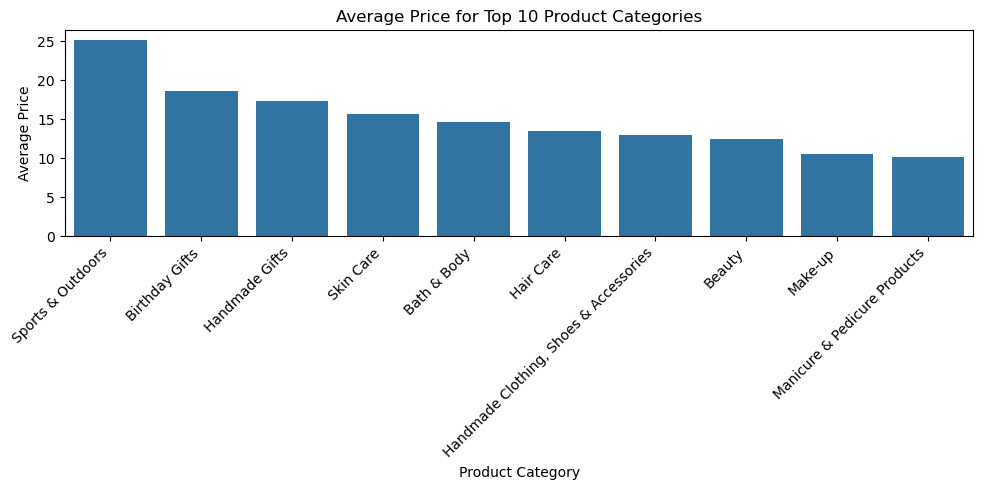

In [35]:
plt.figure(figsize=(10, 5))
sns.barplot(x=avg_price.index, y=avg_price.values)
plt.xticks(rotation=45, ha='right')
plt.ylabel('Average Price')
plt.xlabel('Product Category')
plt.title('Average Price for Top 10 Product Categories')
plt.tight_layout()
plt.show()

In [36]:
#2.2 Which product category commands the highest average price? Don't filter here by top categories.
#awnser: Motherboards is the highest average price category. 

In [37]:
avg_price_by_cat = df_no_outliers.groupby('category')['price'].mean()
top_cat = avg_price_by_cat.idxmax()
top_avg = avg_price_by_cat.max()  
print("Highest‑avg‑price category:", top_cat)
print("Average price:", top_avg)

Highest‑avg‑price category: Motherboards
Average price: 68.77243243243242


# Part 3: Investigating the Interplay Between Product Prices and Ratings


In [38]:
#1.1 Calculate the correlation coefficient between price and stars. 

In [39]:
df_.head()  

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [40]:
corr = df_no_outliers['price'].corr(df_no_outliers['stars'])
print("Correlation between price and stars:", corr)

Correlation between price and stars: -0.07767299878178476


In [41]:
# 1.2 Is there a significant correlation between product price and its rating?

In [ ]:
#There is almost no correlation between product price and rating in this dataset. This is to close to 0. 

In [42]:
#2.1 Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

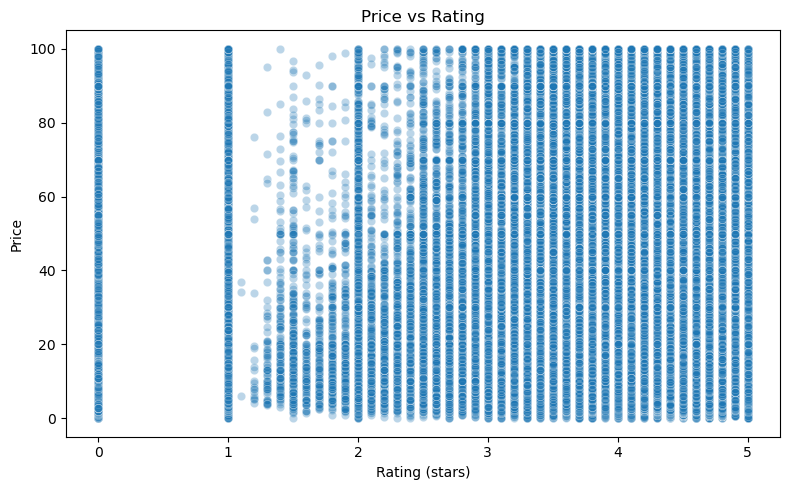

In [43]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_no_outliers,
    x='stars',      
    y='price',      
    alpha=0.3       
)
plt.title('Price vs Rating')
plt.xlabel('Rating (stars)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

In [44]:
# What patterns can you observe?
# almost ratings from 2,5 to 5 stars, the prices are up from cheap to to full price. 
# The higher ratings do not systematically correspond to higher or lower prices. 
# The same patern applies to 0 and 1 stars independetly. 
# price and rating are almost independent in this dataset. 


In [45]:
#2.2 Use a correlation heatmap to visualize correlations between all numerical variables.

In [46]:
num_df = df_no_outliers.select_dtypes(include='number')
corr = num_df.corr() 


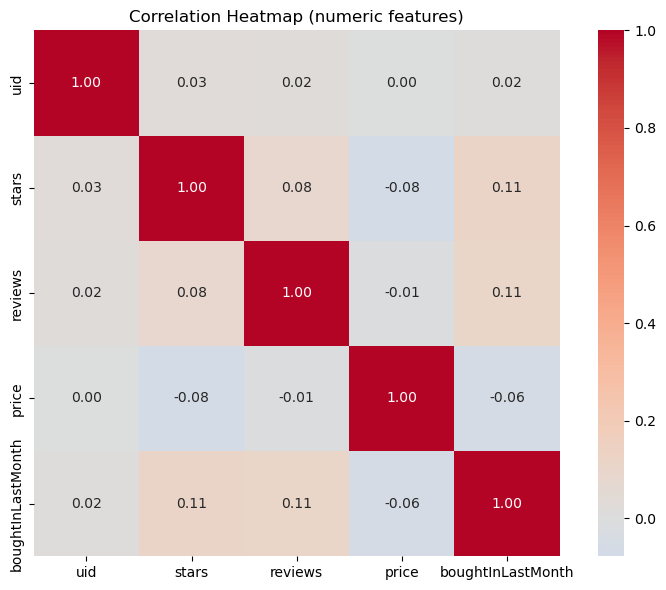

In [47]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,     
    fmt=".2f",
    cmap='coolwarm',
    center=0,
    square=True
)
plt.title('Correlation Heatmap (numeric features)')
plt.tight_layout()
plt.show()

In [48]:
# 2.3 Examine if product prices typically follow a normal distribution using a QQ plot.


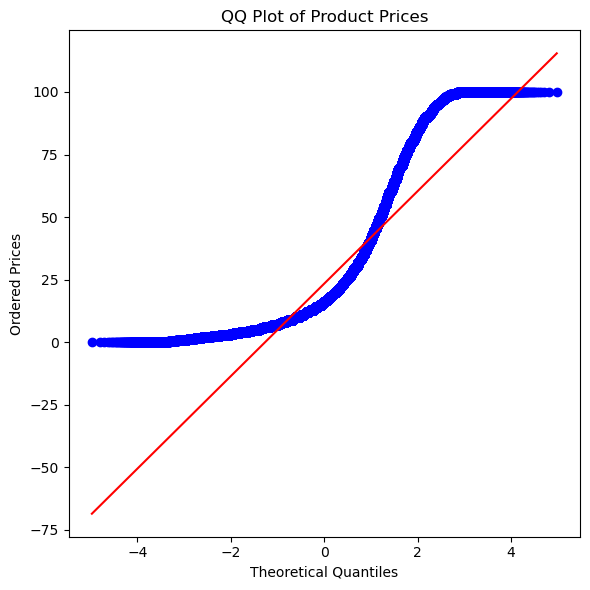

In [49]:
import matplotlib.pyplot as plt
import scipy.stats as stats
plt.figure(figsize=(6, 6))
stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title("QQ Plot of Product Prices")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Ordered Prices")
plt.tight_layout()
plt.show()

Business-centric report summarizing your findings

Best-seller distribution is not independent of product category: some categories have systematically higher or lower best-seller rates than others.
the tests indicate a weak association between product category and best-seller status.
Sports and outdoors is the Best Seller Category.
Desktop PC is the product category that tends to have the highest median price.
Motherboards have the highest average (mean) price category.
There is almost no correlation between product price and rating in this dataset.

